In [2]:
# Load necessary packages and datasets
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.formula.api as smf
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
df = pd.read_csv("./data/weather_with_avg_hourly_flight_delay.csv")
delay = df.copy()
delay.head()

,DATE,HourlyAltimeterSetting,HourlyDewPointTemperature,HourlyDryBulbTemperature,HourlySeaLevelPressure,HourlyStationPressure,HourlyPressureChange,HourlyPressureTendency,HourlyVisibility,HourlyWindSpeed,...,REPORT_TYPE,cloud_1,cloud_0,wind_north,wind_east,wind_south,wind_west,join_time,avg_delay,actual_weather_delay
0,2017-12-01T00:53:00,30.14,40.0,45.0,30.16,29.67,-0.00,3.0,10.0,13.0,...,FM-15,0,1,0,0,1,0,2017120100,-6.250000,0.0
1,2017-12-01T05:53:00,30.08,36.0,42.0,30.10,29.61,0.00,0.0,10.0,10.0,...,FM-15,0,1,0,0,1,0,2017120105,-3.461538,0.0
2,2017-12-01T06:53:00,30.07,35.0,39.0,30.09,29.60,0.04,6.0,10.0,8.0,...,FM-15,0,1,0,0,1,0,2017120106,-5.142857,0.0
3,2017-12-01T07:53:00,30.06,36.0,41.0,30.09,29.59,0.00,0.0,10.0,7.0,...,FM-15,1,0,0,0,1,0,2017120107,10.714286,0.0
4,2017-12-01T08:53:00,30.06,36.0,42.0,30.08,29.59,0.00,0.0,10.0,9.0,...,FM-15,0,1,0,0,1,0,2017120108,4.615385,0.0


In [3]:
# Drop all irrelevant features
delay.drop(['HourlySkyConditions', 'REPORT_TYPE', 'join_time','DATE', 'actual_weather_delay'], axis=1, inplace=True)

In [4]:
# Split the data for training and testing
train_features, test_features, train_outcome, test_outcome = train_test_split(
    delay.drop("avg_delay", axis=1),      # features
    delay.avg_delay,    # outcome
    test_size=0.30, # percentage of data to use as the test set
    random_state=11
)

In [5]:
from sklearn import linear_model
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error

In [6]:
# A grid search to get the best degree parameter of a polynomial regression
score_min = 99999
for order in range(1, 4):
    poly = PolynomialFeatures(degree = order)
    regr = linear_model.LinearRegression()
    new_train = poly.fit_transform(train_features)
    regr.fit(new_train, train_outcome)       
    new_test = poly.fit_transform(test_features)
    result = regr.predict(new_test)
    score = mean_squared_error(result, test_outcome)        
    if score < score_min:
        score_min = score
    print("n={}, MSE = {:<0.5}".format(order, score))

n=1, MSE = 189.95
n=2, MSE = 182.78
n=3, MSE = 765.31


In [7]:
# Using the best degree, train and fit on the training dataset
poly = PolynomialFeatures(degree = 2)
regr = linear_model.LinearRegression()
new_train = poly.fit_transform(train_features)
regr.fit(new_train, train_outcome)
result = regr.predict(new_train)
score = mean_squared_error(result, train_outcome)
print("Mean squared error = ", score)

Mean squared error =  162.60771387738248


In [8]:
# Test the polynomial model with the testing dataset
new_test = poly.fit_transform(test_features)
result = regr.predict(new_test)
score = mean_squared_error(result, test_outcome)
print("Mean squared error = ", score)

Mean squared error =  182.7768797754495


In [9]:
# Make predictions on the average hourly delay
p2 = regr.predict(poly.fit_transform(delay.drop("avg_delay", axis=1)))
delay['prediction'] = p2

In [10]:
import seaborn as sns

C:\Users\liang\Anaconda3\lib\site-packages\scipy\stats\stats.py:1713: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  return np.add.reduce(sorted[indexer] * weights, axis=axis) / sumval


Text(0.5, 0.98, 'Polynomial model fit')

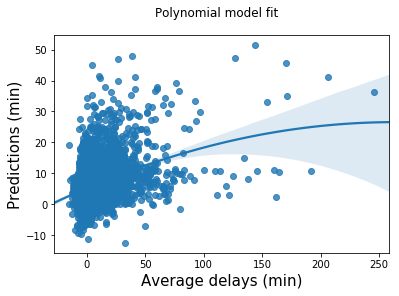

In [11]:
# Plot a fit diagram
sns.regplot(delay.avg_delay, delay.prediction, data=delay, order=2)
plt.xlabel('Average delays (min)', fontsize = 15)
plt.ylabel('Predictions (min)', fontsize = 15)
plt.suptitle("Polynomial model fit")

In [12]:
# Calculate the r squared value 
d_res = delay.avg_delay-delay.prediction
SSresid = sum(pow(d_res, 2))
SStotal = len(delay.avg_delay) * np.var(delay.avg_delay)
r_sqr = 1 - SSresid / SStotal
print(r_sqr)

0.1303642204758334


In [13]:
from sklearn.metrics import mean_absolute_error

In [14]:
# Calculate the mean absolute error
mean_absolute_error(delay.prediction, delay.avg_delay)

7.949535489449717

In [15]:
# Calculate the mean squared error
mean_squared_error(delay.prediction, delay.avg_delay)

168.65981456213396

In [16]:
plt.figure(figsize = (300, 100))
delay.prediction.plot(label="Predictions", fontsize = 200)
delay.avg_delay.plot(label="Actual")

plt.suptitle("Polynomial Predicted Delay vs. Actual average delay", fontsize = 200)
plt.legend(fontsize = 200)
plt.show()

In [17]:
# Calculate the percentage of flights that falls within 15 mins interval centered at 15 minutes interval
count = 0
for i in range(len(delay.avg_delay)):
    if abs(delay.avg_delay[i]-p2[i]) > 15: count += 1
'{:.2f}%'.format(100 - count / len(p2) * 100)

'90.21%'

In [18]:
regr.coef_

array([-4.01177486e-04,  1.75318466e+04, -4.97321990e+01, -5.54886323e+01,
        3.82782479e+03, -2.19826974e+04,  1.97694947e+03,  7.26441809e-01,
       -4.55560533e+01, -4.20785591e+00, -4.03760156e+03,  1.10379850e+02,
       -4.63876789e-01, -4.28816761e-01, -8.17611952e+01,  8.17611797e+01,
       -7.17905632e+00,  3.20202198e+01,  3.89065451e+00, -2.87318134e+01,
       -2.54404746e+04,  3.20540446e+01, -1.77071121e+01,  3.65043340e+04,
        1.35119864e+04, -4.05565586e+03,  5.06369395e+01,  4.58002132e+01,
       -1.48496774e+01, -3.83237865e+03,  1.46631673e+01, -1.27350032e-01,
       -1.08544748e+01,  8.86458464e+03,  8.66726208e+03,  4.39784357e+03,
        4.41121505e+03,  4.26339177e+03,  4.45939631e+03, -3.80040401e-01,
       -7.10149245e-02, -3.05500001e+01,  7.94666202e-01, -3.54975057e+01,
        1.23157899e-01, -9.84391567e-02, -7.70934717e-02,  1.41032274e+01,
        9.65060768e-01, -3.99987595e-03,  1.67599209e-01, -2.47011256e+01,
       -2.50309695e+01, -